In [1]:
# Install dependencies
%pip install "scikit-learn==1.9.1" "numpy==2.3.5" "scipy==1.17.0" "pandas==2.2.3" "matplotlib==3.10.8" "nltk==3.10.4" "umap-learn==0.5.12" "spacy==3.8.18" "spacy-lookups-data==1.0.5"

**Load of the dataset and verification**

In [2]:
from pathlib import Path
from time import perf_counter
from importlib.metadata import version
import hashlib
import io
import re
import tarfile
import unicodedata
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.base import clone

SEED = 2026
N_JOBS = 1  # Conservative memory use; increase only after checking your machine.
DATA_DIR = Path('data')
DATA_DIR.mkdir(exist_ok=True)
CLASS_NAMES = ['Negative', 'Positive']  # Explicit mapping: 0, 1.
NEG, POS, INK, MUTED = '#d26936', '#286fb5', '#233247', '#697586'
CLASS_COLORS = [NEG, POS]
MODEL_COLORS = [POS, NEG, '#22856b', '#8060af', '#ad5d87', '#7c7860']
plt.rcParams.update({
    'figure.figsize': (9, 4.3), 'figure.dpi': 115,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titleweight': 'bold', 'axes.titlesize': 12,
    'font.size': 10.5, 'axes.axisbelow': True,
    'grid.color': '#e4e7ec', 'grid.alpha': 0.8,
})
print('Package versions:')
for package in ['scikit-learn', 'numpy', 'scipy', 'pandas', 'matplotlib', 'nltk', 'spacy', 'spacy-lookups-data', 'umap-learn']:
    print(f'{package}: {version(package)}')

Package versions:
scikit-learn: 1.9.1
numpy: 2.3.5
scipy: 1.17.0
pandas: 2.2.3
matplotlib: 3.10.8
nltk: 3.10.4
spacy: 3.8.18
spacy-lookups-data: 1.0.5
umap-learn: 0.5.12


In [3]:
DATA_URL = 'https://www.cs.cornell.edu/people/pabo/movie-review-data/review_polarity.tar.gz'
ARCHIVE = DATA_DIR / 'review_polarity.tar.gz'
EXPECTED_SHA256 = 'fc0dccc2671af5db3c5d8f81f77a1ebfec953ecdd422334062df61ede36b2179'
if not ARCHIVE.exists():
    try:
        with urllib.request.urlopen(DATA_URL, timeout=60) as response:
            payload = response.read()
    except OSError as exc:
        raise RuntimeError('Put the supplied review_polarity.tar.gz in data/ and rerun.') from exc
    if hashlib.sha256(payload).hexdigest() != EXPECTED_SHA256:
        raise ValueError('Unexpected download checksum.')
    ARCHIVE.write_bytes(payload)
payload = ARCHIVE.read_bytes()
assert hashlib.sha256(payload).hexdigest() == EXPECTED_SHA256
print('Verified original Cornell archive:', len(payload), 'bytes')

Verified original Cornell archive: 3127238 bytes


In [4]:
rows = []
with tarfile.open(fileobj=io.BytesIO(payload), mode='r:gz') as archive:
    for member in sorted(archive.getmembers(), key=lambda item: item.name):
        parts = Path(member.name).parts
        if (member.isfile() and len(parts) == 3 and parts[0] == 'txt_sentoken'
                and parts[1] in {'neg', 'pos'} and parts[2].endswith('.txt')):
            rows.append({'text': archive.extractfile(member).read().decode('utf-8'),
                         'label': int(parts[1] == 'pos'), 'file': member.name})
reviews = pd.DataFrame(rows)
assert reviews.shape[0] == 2000
assert reviews.label.value_counts().sort_index().tolist() == [1000, 1000]
assert reviews.text.str.strip().ne('').all()
dedup_text = reviews.text.str.replace(r'\s+', ' ', regex=True).str.strip()
assert not dedup_text.duplicated().any(), 'Resolve duplicated texts before splitting.'

# Reserve the outer holdout immediately to protect it during exploration.
# The later Split dataset section explains and visualizes both split levels.
trainval, sealed_test = train_test_split(
    reviews, test_size=0.15, stratify=reviews.label, random_state=SEED)
trainval = trainval.reset_index(drop=True)
X_trainval = trainval.text.to_numpy()
y_trainval = trainval.label.to_numpy()
print(f'{len(reviews)} reviews: {len(trainval)} training + validation; {len(sealed_test)} sealed test.')
print('Class mapping:', dict(enumerate(CLASS_NAMES)))
print('Training + validation review excerpt:', X_trainval[0][:280].replace('\n', ' '))

2000 reviews: 1700 training + validation; 300 sealed test.
Class mapping: {0: 'Negative', 1: 'Positive'}
Training + validation review excerpt: it's always a bad sign when the core audience of a film -- children -- are either walking out early or are half-asleep when the credits roll at the end of a film .  that about sums up the dreadful ugliness of 102 dalmatians , a cold pea soup of cute animals , stupid home alone an


**Split of the dataset**

In [5]:
train, dev = train_test_split(trainval, test_size=0.235, stratify=trainval.label, random_state=SEED)

**Text preprocessing**

In [6]:
def normalize_text(text):
    text = unicodedata.normalize('NFKC', str(text)).replace('’', "'").lower()
    # Expand the irregular stems before the generic n't rule.
    text = re.sub(r"\bcan't\b", 'can not', text)
    text = re.sub(r"\bwon't\b", 'will not', text)
    text = re.sub(r"\bshan't\b", 'shall not', text)
    text = re.sub(r"\bcannot\b", 'can not', text)
    # Also handle already tokenized contractions found in processed corpora.
    text = re.sub(r"\bca\s+n't\b", 'can not', text)
    text = re.sub(r"\bwo\s+n't\b", 'will not', text)
    text = re.sub(r"n['’]t\b", ' not', text)
    return re.sub(r'\s+', ' ', text).strip()

preprocess_examples = ["I can't recommend this film.", "This isn't good.",
                       "I did not like it.", "It wasn't boring."]
display(pd.DataFrame({'original': preprocess_examples,
                      'normalized': [normalize_text(t) for t in preprocess_examples]}))
assert normalize_text("I can't recommend this film.") == 'i can not recommend this film.'
assert normalize_text("This isn't good.") == 'this is not good.'
assert normalize_text('I can’t recommend this film.') == 'i can not recommend this film.'
assert normalize_text("it did n't work") == 'it did not work'

,original,normalized
0,I can't recommend this film.,i can not recommend this film.
1,This isn't good.,this is not good.
2,I did not like it.,i did not like it.
3,It wasn't boring.,it was not boring.


In [7]:
print(len(train["text"]))
print(len(dev["text"]))
print(len(sealed_test["text"]))

1300
400
300


In [8]:
train_normalized = [normalize_text(review) for review in train["text"]]
dev_normalized = [normalize_text(review) for review in dev["text"]]
test_normalized = [normalize_text(review) for review in sealed_test["text"]]

train["text_normalized"] = train_normalized
dev["text_normalized"] = dev_normalized
sealed_test["text_normalized"] = test_normalized

In [9]:
print(len(train["text_normalized"]))
print(len(dev["text_normalized"]))
print(len(sealed_test["text_normalized"]))

1300
400
300


**Boolean feature representation**

In [10]:
from sklearn.feature_extraction.text import CountVectorizer
def make_boolean_vectorizer():
    vectorizer = CountVectorizer(ngram_range=(1, 1), binary=True)
    return vectorizer

vectorizerB = make_boolean_vectorizer()
vectorB_train = vectorizerB.fit_transform(train["text_normalized"])
vectorB_dev = vectorizerB.transform(dev["text_normalized"])
vectorB_test = vectorizerB.transform(sealed_test["text_normalized"])


In [11]:
print(vectorB_train.shape)
print(vectorB_dev.shape)
print(vectorB_test.shape)

(1300, 33187)
(400, 33187)
(300, 33187)


**tf-idf with unigrams feature representation**

In [12]:
from sklearn.feature_extraction.text import TfidfVectorizer

def make_tfidf_U():
    return TfidfVectorizer(ngram_range=(1,1), min_df=2, max_features=5000,
                           sublinear_tf=True,
                           stop_words=None, norm='l2')

vectorizer_tfidf_U = make_tfidf_U()
vector_tfidf_U_train = vectorizer_tfidf_U.fit_transform(train["text_normalized"])
vector_tfidf_U_dev = vectorizer_tfidf_U.transform(dev["text_normalized"])
vector_tfidf_U_test = vectorizer_tfidf_U.transform(sealed_test["text_normalized"])

In [13]:
print(vector_tfidf_U_train.shape)
print(vector_tfidf_U_dev.shape)
print(vector_tfidf_U_test.shape)

(1300, 5000)
(400, 5000)
(300, 5000)


**tf-idf with unigrams and bigrams feature representation**

In [14]:
from sklearn.feature_extraction.text import TfidfVectorizer

def make_tfidf_UB():
    return TfidfVectorizer(ngram_range=(1,2), min_df=2, max_features=5000,
                           sublinear_tf=True,
                           stop_words=None, norm='l2')

vectorizer_tfidf_UB = make_tfidf_UB()
vector_tfidf_UB_train = vectorizer_tfidf_UB.fit_transform(train["text_normalized"])
vector_tfidf_UB_dev = vectorizer_tfidf_UB.transform(dev["text_normalized"])
vector_tfidf_UB_test = vectorizer_tfidf_UB.transform(sealed_test["text_normalized"])

In [15]:
print(vector_tfidf_UB_train.shape)
print(vector_tfidf_UB_dev.shape)
print(vector_tfidf_UB_test.shape)

(1300, 5000)
(400, 5000)
(300, 5000)


**Model evaluation**

In [16]:
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             ConfusionMatrixDisplay, average_precision_score)
results = {}
fitted_models = {}

y_train = train["label"]
y_val = dev["label"]

def evaluate(model, name, X_tr, X_va):
    start = perf_counter()
    # G06 — Learn the classifier using training feature vectors and their correct labels.
    model.fit(X_tr, y_train)
    fit_seconds = perf_counter() - start
    start = perf_counter()
    val_prediction = model.predict(X_va)
    prediction_seconds = perf_counter() - start
    train_prediction = model.predict(X_tr)
    results[name] = {
        'Train macro F1': f1_score(y_train, train_prediction, average='macro', zero_division=0),
        'Validation macro F1': f1_score(y_val, val_prediction, average='macro', zero_division=0),
        'Validation positive F1': f1_score(y_val, val_prediction, pos_label=1, zero_division=0),
        'Validation accuracy': accuracy_score(y_val, val_prediction),
        'Classifier training ms': fit_seconds * 1000,
        'Classifier predict ms': prediction_seconds * 1000,
    }
    fitted_models[name] = model
    print(f"{name}: train macro F1 {results[name]['Train macro F1']:.3f}; "
          f"validation macro F1 {results[name]['Validation macro F1']:.3f}")
    return model

**Majority baseline**

Majority baseline: train macro F1 0.333; validation macro F1 0.333


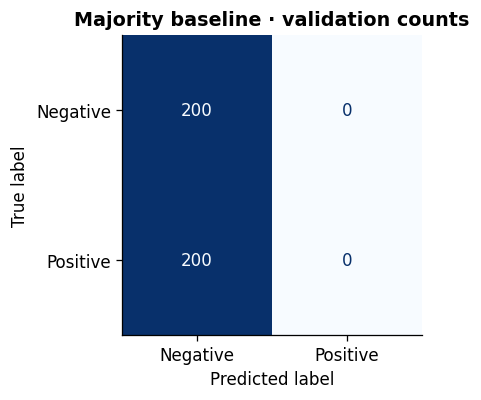

In [17]:
from sklearn.dummy import DummyClassifier

baseline = evaluate(DummyClassifier(strategy='most_frequent'),
                    'Majority baseline', vectorB_train, vectorB_dev)

fig, ax = plt.subplots(figsize=(4.8, 3.6))
ConfusionMatrixDisplay.from_predictions(y_val, baseline.predict(vectorB_dev),
    labels=[0, 1], display_labels=CLASS_NAMES, cmap='Blues', colorbar=False, ax=ax)
ax.set_title('Majority baseline · validation counts')
plt.tight_layout(); plt.show()

**Hyperparameter tuning**

In [18]:
from sklearn.linear_model import LogisticRegression

vals_c = [0.01, 0.1, 0.3, 0.5, 0.7, 1, 10, 30]
print("Boolean hyper parameters tuning :")
for c in vals_c :
  evaluate(LogisticRegression(
    C=c, solver='lbfgs', max_iter=1000), f"Logistic regression boolean vectors C = {c}",
                      vectorB_train, vectorB_dev)

print("\ntfidf unigrams hyper parameters tuning :")
for c in vals_c :
  evaluate(LogisticRegression(
    C=c, solver='lbfgs', max_iter=1000), f"Logistic regression tfidf unigrams vectors C = {c}",
                      vector_tfidf_U_train, vector_tfidf_U_dev)

print("\ntfidf uni+bigrams hyper parameters tuning :")
for c in vals_c :
  evaluate(LogisticRegression(
    C=c, solver='lbfgs', max_iter=1000), f"Logistic regression tfidf uni+bigrams vectors C = {c}",
                      vector_tfidf_UB_train, vector_tfidf_UB_dev)



Boolean hyper parameters tuning :
Logistic regression boolean vectors C = 0.01: train macro F1 0.990; validation macro F1 0.837
Logistic regression boolean vectors C = 0.1: train macro F1 1.000; validation macro F1 0.842
Logistic regression boolean vectors C = 0.3: train macro F1 1.000; validation macro F1 0.840
Logistic regression boolean vectors C = 0.5: train macro F1 1.000; validation macro F1 0.837
Logistic regression boolean vectors C = 0.7: train macro F1 1.000; validation macro F1 0.837
Logistic regression boolean vectors C = 1: train macro F1 1.000; validation macro F1 0.837
Logistic regression boolean vectors C = 10: train macro F1 1.000; validation macro F1 0.850
Logistic regression boolean vectors C = 30: train macro F1 1.000; validation macro F1 0.850

tfidf unigrams hyper parameters tuning :
Logistic regression tfidf unigrams vectors C = 0.01: train macro F1 0.914; validation macro F1 0.797
Logistic regression tfidf unigrams vectors C = 0.1: train macro F1 0.924; validati

**Train the final logistic regression models**

In [19]:
clf_lr_B = evaluate(LogisticRegression(
    C=10, solver='lbfgs', max_iter=1000), 'Logistic regression boolean vectors', vectorB_train, vectorB_dev)

Logistic regression boolean vectors: train macro F1 1.000; validation macro F1 0.850


In [20]:
clf_lr_tfidf_U = evaluate(LogisticRegression(
    C=10, solver='lbfgs', max_iter=1000), 'Logistic regression tfidf unigrams vectors', vector_tfidf_U_train, vector_tfidf_U_dev)

Logistic regression tfidf unigrams vectors: train macro F1 1.000; validation macro F1 0.852


In [21]:
clf_lr_tfidf_UB = evaluate(LogisticRegression(
    C=10, solver='lbfgs', max_iter=1000), 'Logistic regression tfidf uni+bigrams vectors', vector_tfidf_UB_train, vector_tfidf_UB_dev)

Logistic regression tfidf uni+bigrams vectors: train macro F1 1.000; validation macro F1 0.885


**Evaluation on train, dev and test sets**

In [22]:
def scores(model, X_train, X_dev, X_test):
  #
  train_pred = model.predict(X_train)
  train_proba = model.predict_proba(X_train)
  report_train = classification_report(train["label"], train_pred, labels=[0, 1],
                  target_names=CLASS_NAMES, output_dict=True, zero_division=0)

  train_pr_AUC_neg = average_precision_score((train["label"] == 0).astype(int),
                                             train_proba[:, 0])
  train_pr_AUC_pos = average_precision_score((train["label"] == 1).astype(int),
                                             train_proba[:, 1])
  train_macro_precision = report_train["macro avg"]["precision"]
  train_macro_recall = report_train["macro avg"]["recall"]
  train_macro_F1 = report_train["macro avg"]["f1-score"]
  train_macro_pr_AUC = (train_pr_AUC_neg + train_pr_AUC_pos) / 2

  #
  dev_pred = model.predict(X_dev)
  dev_proba = model.predict_proba(X_dev)
  report_dev = classification_report(dev["label"], dev_pred, labels=[0, 1],
                  target_names=CLASS_NAMES, output_dict=True, zero_division=0)

  dev_pr_AUC_neg = average_precision_score((dev["label"] == 0).astype(int),
                                           dev_proba[:, 0])
  dev_pr_AUC_pos = average_precision_score((dev["label"] == 1).astype(int),
                                           dev_proba[:, 1])
  dev_macro_precision = report_dev["macro avg"]["precision"]
  dev_macro_recall = report_dev["macro avg"]["recall"]
  dev_macro_F1 = report_dev["macro avg"]["f1-score"]
  dev_macro_pr_AUC = (dev_pr_AUC_neg + dev_pr_AUC_pos) / 2

  #
  test_pred = model.predict(X_test)
  test_proba = model.predict_proba(X_test)
  report_test = classification_report(sealed_test["label"], test_pred,
                      labels=[0, 1], target_names=CLASS_NAMES, output_dict=True,
                      zero_division=0)

  test_pr_AUC_neg = average_precision_score((sealed_test["label"] == 0).astype(int),
                                            test_proba[:, 0])
  test_pr_AUC_pos = average_precision_score((sealed_test["label"] == 1).astype(int),
                                            test_proba[:, 1])
  test_macro_precision = report_test["macro avg"]["precision"]
  test_macro_recall = report_test["macro avg"]["recall"]
  test_macro_F1 = report_test["macro avg"]["f1-score"]
  test_macro_pr_AUC = (test_pr_AUC_neg + test_pr_AUC_pos) / 2

  return (report_train, report_dev, report_test, train_pr_AUC_neg, train_pr_AUC_pos,
        dev_pr_AUC_neg, dev_pr_AUC_pos, test_pr_AUC_neg, test_pr_AUC_pos)

In [23]:
baseline_scores = scores(baseline, vectorB_train, vectorB_dev, vectorB_test)
boolean_scores = scores(clf_lr_B, vectorB_train, vectorB_dev, vectorB_test)
tfidf_U_scores = scores(clf_lr_tfidf_U, vector_tfidf_U_train, vector_tfidf_U_dev, vector_tfidf_U_test)
tfidf_UB_scores = scores(clf_lr_tfidf_UB, vector_tfidf_UB_train, vector_tfidf_UB_dev, vector_tfidf_UB_test)

**Results tables**

In [24]:
def make_row(name, s, i):
    report = s[i]
    auc_neg = s[3 + 2*i]
    auc_pos = s[4 + 2*i]

    return {
        "Classifier": name,
        "Negative Precision": report["Negative"]["precision"],
        "Negative Recall": report["Negative"]["recall"],
        "Negative F1": report["Negative"]["f1-score"],
        "Negative PR-AUC": auc_neg,
        "Positive Precision": report["Positive"]["precision"],
        "Positive Recall": report["Positive"]["recall"],
        "Positive F1": report["Positive"]["f1-score"],
        "Positive PR-AUC": auc_pos,
        "Macro Precision": report["macro avg"]["precision"],
        "Macro Recall": report["macro avg"]["recall"],
        "Macro F1": report["macro avg"]["f1-score"],
        "Macro PR-AUC": (auc_neg + auc_pos) / 2
    }

In [25]:
table_train = pd.DataFrame([
    make_row("Majority baseline", baseline_scores, 0),
    make_row("Logistic Regression Boolean", boolean_scores, 0),
    make_row("Logistic Regression TF-IDF U", tfidf_U_scores, 0),
    make_row("Logistic Regression TF-IDF U+B", tfidf_UB_scores, 0)
])

table_dev = pd.DataFrame([
    make_row("Majority baseline", baseline_scores, 1),
    make_row("Logistic Regression Boolean", boolean_scores, 1),
    make_row("Logistic Regression TF-IDF U", tfidf_U_scores, 1),
    make_row("Logistic Regression TF-IDF U+B", tfidf_UB_scores, 1)
])

table_test = pd.DataFrame([
    make_row("Majority baseline", baseline_scores, 2),
    make_row("Logistic Regression Boolean", boolean_scores, 2),
    make_row("Logistic Regression TF-IDF U", tfidf_U_scores, 2),
    make_row("Logistic Regression TF-IDF U+B", tfidf_UB_scores, 2)
])

display(table_train.round(3))
display(table_dev.round(3))
display(table_test.round(3))

,Classifier,Negative Precision,Negative Recall,Negative F1,Negative PR-AUC,Positive Precision,Positive Recall,Positive F1,Positive PR-AUC,Macro Precision,Macro Recall,Macro F1,Macro PR-AUC
0,Majority baseline,0.5,1.0,0.667,0.5,0.0,0.0,0.0,0.5,0.25,0.5,0.333,0.5
1,Logistic Regression Boolean,1.0,1.0,1.000,1.0,1.0,1.0,1.0,1.0,1.00,1.0,1.000,1.0
2,Logistic Regression TF-IDF U,1.0,1.0,1.000,1.0,1.0,1.0,1.0,1.0,1.00,1.0,1.000,1.0
3,Logistic Regression TF-IDF U+B,1.0,1.0,1.000,1.0,1.0,1.0,1.0,1.0,1.00,1.0,1.000,1.0


,Classifier,Negative Precision,Negative Recall,Negative F1,Negative PR-AUC,Positive Precision,Positive Recall,Positive F1,Positive PR-AUC,Macro Precision,Macro Recall,Macro F1,Macro PR-AUC
0,Majority baseline,0.500,1.000,0.667,0.500,0.000,0.00,0.000,0.500,0.250,0.500,0.333,0.500
1,Logistic Regression Boolean,0.843,0.860,0.851,0.918,0.857,0.84,0.848,0.924,0.850,0.850,0.850,0.921
2,Logistic Regression TF-IDF U,0.865,0.835,0.850,0.934,0.841,0.87,0.855,0.938,0.853,0.852,0.852,0.936
3,Logistic Regression TF-IDF U+B,0.881,0.890,0.886,0.940,0.889,0.88,0.884,0.945,0.885,0.885,0.885,0.943


,Classifier,Negative Precision,Negative Recall,Negative F1,Negative PR-AUC,Positive Precision,Positive Recall,Positive F1,Positive PR-AUC,Macro Precision,Macro Recall,Macro F1,Macro PR-AUC
0,Majority baseline,0.500,1.000,0.667,0.500,0.000,0.000,0.000,0.500,0.250,0.500,0.333,0.500
1,Logistic Regression Boolean,0.861,0.907,0.883,0.934,0.901,0.853,0.877,0.945,0.881,0.880,0.880,0.939
2,Logistic Regression TF-IDF U,0.899,0.893,0.896,0.951,0.894,0.900,0.897,0.946,0.897,0.897,0.897,0.949
3,Logistic Regression TF-IDF U+B,0.839,0.833,0.836,0.935,0.834,0.840,0.837,0.936,0.837,0.837,0.837,0.936


**Learning curves**

In [26]:
from sklearn.model_selection import learning_curve, LearningCurveDisplay
from sklearn.pipeline import make_pipeline
from sklearn.base import clone

X_all = np.concatenate([
    train["text_normalized"].to_numpy(),
    dev["text_normalized"].to_numpy()
])

y_all = np.concatenate([
    train["label"].to_numpy(),
    dev["label"].to_numpy()
])

train_indices = np.arange(len(train))
dev_indices = np.arange(len(train), len(train) + len(dev))

cv_split = [(train_indices, dev_indices)]


In [27]:
def plot_learning_curve(name, vectorizer, classifier):

    estimator = make_pipeline(clone(vectorizer), clone(classifier))

    train_sizes, train_scores, dev_scores = learning_curve(
        estimator,
        X_all,
        y_all,
        cv=cv_split,
        train_sizes=np.linspace(0.1, 1.0, 10),
        scoring="f1_macro",
        shuffle=True,
        random_state=SEED
    )

    display = LearningCurveDisplay(
        train_sizes=train_sizes,
        train_scores=train_scores,
        test_scores=dev_scores,
        score_name="Macro F1"
    )

    display.plot()
    plt.title(name)
    plt.legend(["Train", "Dev"])
    plt.show()

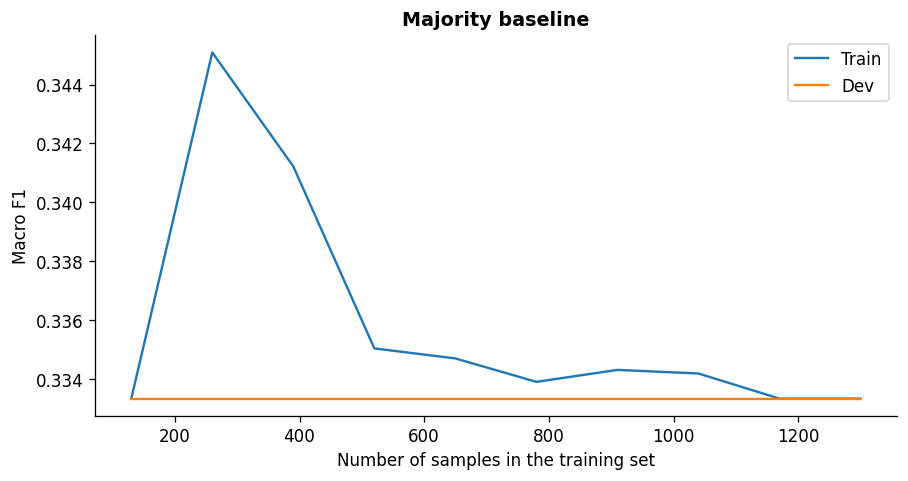

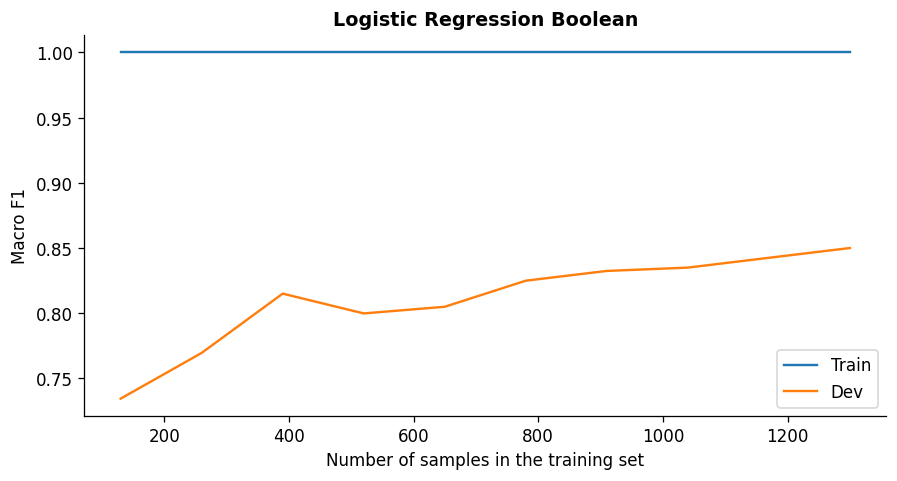

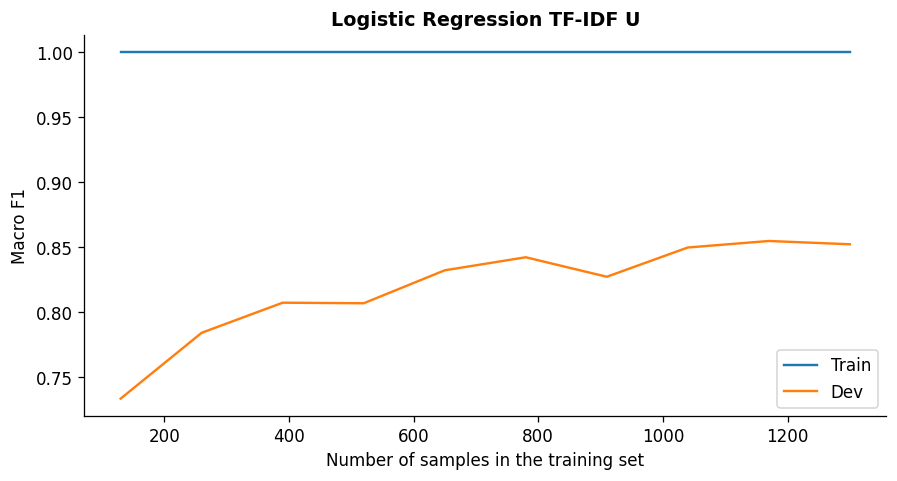

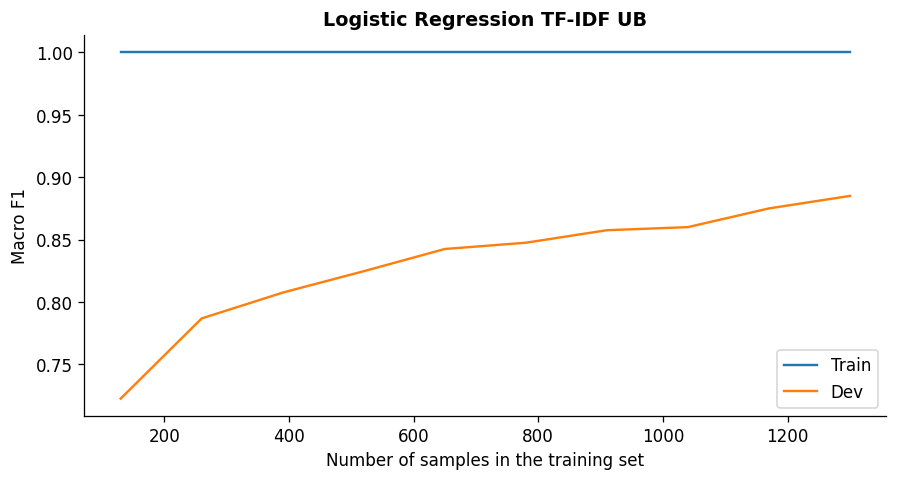

In [28]:
plot_learning_curve("Majority baseline", vectorizerB, baseline)

plot_learning_curve("Logistic Regression Boolean",
                    vectorizerB, clf_lr_B)

plot_learning_curve("Logistic Regression TF-IDF U",
                    vectorizer_tfidf_U, clf_lr_tfidf_U)

plot_learning_curve("Logistic Regression TF-IDF UB",
                    vectorizer_tfidf_UB, clf_lr_tfidf_UB)

**Dataset statistics**

In [29]:
print("Statistics about the datasets : \n\nNumber of documents:")
print("Train:", len(train))
print("Dev:", len(dev))
print("Test:", len(sealed_test))
print("Total:", len(reviews))

average_length = reviews["text"].apply(lambda x: len(x.split())).mean()

print("\nAverage document length:", round(average_length, 2), "words")

print("\nVocabulary sizes:")
print("Boolean:", len(vectorizerB.vocabulary_))
print("TF-IDF unigrams:", len(vectorizer_tfidf_U.vocabulary_))
print("TF-IDF unigrams+bigrams:", len(vectorizer_tfidf_UB.vocabulary_))

Statistics about the datasets : 

Number of documents:
Train: 1300
Dev: 400
Test: 300
Total: 2000

Average document length: 746.34 words

Vocabulary sizes:
Boolean: 33187
TF-IDF unigrams: 5000
TF-IDF unigrams+bigrams: 5000
